Overall Model Accuracy: 0.8092
ROC-AUC Performance: 0.7412

              precision    recall  f1-score   support

           0       0.88      0.89      0.89      8379
           1       0.36      0.34      0.35      1478

    accuracy                           0.81      9857
   macro avg       0.62      0.61      0.62      9857
weighted avg       0.81      0.81      0.81      9857



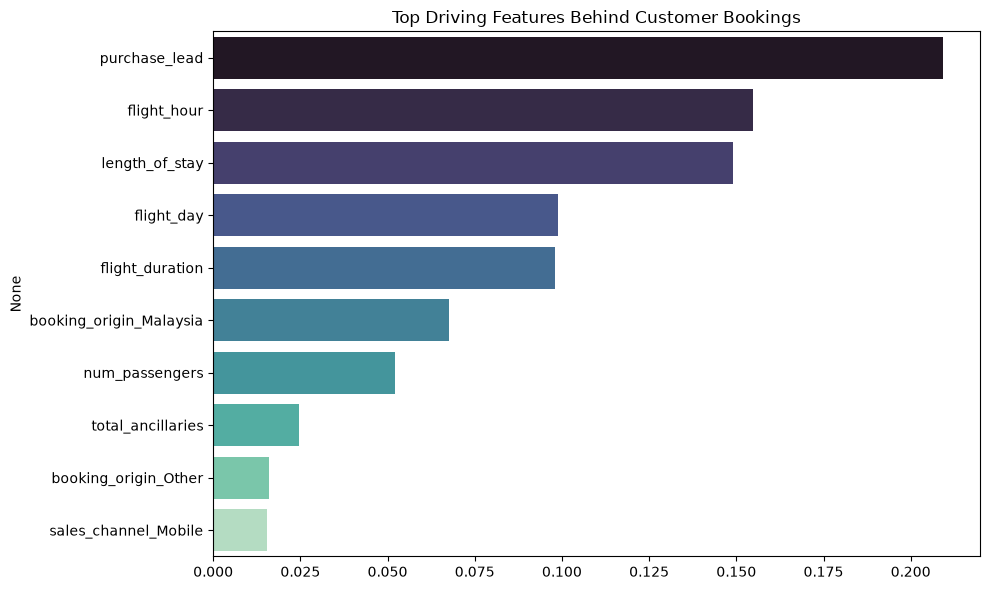

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score, roc_auc_score

os.makedirs('../images', exist_ok=True)

# Load booking transaction dataset using exact relative folder pathways
df = pd.read_csv('../data/customer_booking.csv', encoding='ISO-8859-1')
df = df.drop_duplicates()

# Apply numerical mappings to days
day_map = {"Mon": 1, "Tue": 2, "Wed": 3, "Thu": 4, "Fri": 5, "Sat": 6, "Sun": 7}
df["flight_day"] = df["flight_day"].map(day_map)
df["total_ancillaries"] = df["wants_extra_baggage"] + df["wants_preferred_seat"] + df["wants_in_flight_meals"]

# Handle cardinality by grouping minor origins as 'Other'
top_origins = df["booking_origin"].value_counts().nlargest(12).index
df["booking_origin"] = np.where(df["booking_origin"].isin(top_origins), df["booking_origin"], "Other")
df = df.drop(columns=["route"])

# One-hot encode string classes
df_processed = pd.get_dummies(df, columns=["sales_channel", "trip_type", "booking_origin"], drop_first=True)

# Split target features
X = df_processed.drop(columns=["booking_complete"])
y = df_processed["booking_complete"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Fit ensemble Random Forest model using balanced weight configurations
model = RandomForestClassifier(n_estimators=250, class_weight="balanced", random_state=42, n_jobs=-1)
model.fit(X_train, y_train)

# Output evaluation metrics
preds = model.predict(X_test)
probs = model.predict_proba(X_test)[:, 1]
print(f"Overall Model Accuracy: {accuracy_score(y_test, preds):.4f}")
print(f"ROC-AUC Performance: {roc_auc_score(y_test, probs):.4f}\n")
print(classification_report(y_test, preds))

# Export visual feature charts
feature_imp = pd.Series(model.feature_importances_, index=X.columns).nlargest(10)
plt.figure(figsize=(10, 6))
sns.barplot(x=feature_imp.values, y=feature_imp.index, hue=feature_imp.index, palette="mako", legend=False)
plt.title("Top Driving Features Behind Customer Bookings")
plt.tight_layout()
plt.savefig('../images/feature_importance.png')
plt.show()
